This notebook will be used to implement Modality-Attentive Meta-Embedding Generator and integrate it into a single unified pipeline that handles warm-start and cold-start items without separate models.

In [34]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [127]:
import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from datetime import datetime


In [36]:
# Base paths (standard structure)
base_dir = "/content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M"
preprocessed_dir = os.path.join(base_dir, "AntM2C_preprocessed")
fusion_artifacts_dir = os.path.join(base_dir, "fusion_artifacts")

# Key artifact paths
fusion_config_path = os.path.join(fusion_artifacts_dir, "fusion_config.json")

df_id_encoded_path = os.path.join(preprocessed_dir, "split_features", "df_id_encoded.pkl")

text_embeddings_path = os.path.join(preprocessed_dir, "text_embeddings.npy")
time_features_path = os.path.join(preprocessed_dir, "time_features_final.pt")

time_feature_cols_path = os.path.join(preprocessed_dir, "time_feature_columns.json")

image_embeddings_path = os.path.join(base_dir, "image_embeddings_vit_base_aligned.pt")
image_missing_mask_path = os.path.join(base_dir, "image_missing_mask.pt")

print("base_dir:", base_dir)
print("preprocessed_dir:", preprocessed_dir)
print("fusion_artifacts_dir:", fusion_artifacts_dir)

base_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M
preprocessed_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed
fusion_artifacts_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/fusion_artifacts


In [37]:
# Quick existence checks
paths_to_check = {
    "fusion_config.json": fusion_config_path,
    "df_id_encoded.pkl": df_id_encoded_path,
    "text_embeddings.npy": text_embeddings_path,
    "time_features_final.pt": time_features_path,
    "time_feature_columns.json": time_feature_cols_path,
    "image_embeddings_vit_base_aligned.pt": image_embeddings_path,
    "image_missing_mask.pt": image_missing_mask_path
}

for name, p in paths_to_check.items():
    print(f"{name} exists? -> {os.path.exists(p)} | {p}")

fusion_config.json exists? -> True | /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/fusion_artifacts/fusion_config.json
df_id_encoded.pkl exists? -> True | /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed/split_features/df_id_encoded.pkl
text_embeddings.npy exists? -> True | /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed/text_embeddings.npy
time_features_final.pt exists? -> True | /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed/time_features_final.pt
time_feature_columns.json exists? -> True | /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed/time_feature_columns.json
image_embeddings_vit_base_aligned.pt exists? -> True | /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/image_embeddings_vit_base_aligned.pt
image_missing_mask.pt exists? ->

In [38]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cpu


In [39]:
# Load fusion config + vocab sizes
with open(fusion_config_path, "r") as f:
    fusion_config = json.load(f)

print("--- Loaded fusion_config.json ---")
for k in ["num_users", "num_items", "num_scenes", "text_dim", "image_dim", "time_dim", "d_model", "num_experts", "hidden_dim"]:
    if k in fusion_config:
        print(f"{k}: {fusion_config[k]}")

--- Loaded fusion_config.json ---
num_users: 67615
num_items: 59142
num_scenes: 5
text_dim: 1536
image_dim: 768
time_dim: 5
d_model: 256
num_experts: 4
hidden_dim: 256


In [40]:
# Load df_id_encoded + validate columns
df_id = pd.read_pickle(df_id_encoded_path)
print("Loaded df_id_encoded.pkl:", df_id.shape)
print("Columns:", list(df_id.columns))

required_cols = ["user_id_idx", "item_id_idx"]
scene_candidates = ["scene_idx", "scene_id_idx"]

assert all(c in df_id.columns for c in required_cols), f"Missing required cols. Expected {required_cols}"
scene_col = next((c for c in scene_candidates if c in df_id.columns), None)
assert scene_col is not None, f"Missing scene column. Expected one of {scene_candidates}"

print("Detected scene column:", scene_col)

df_id.head()

Loaded df_id_encoded.pkl: (3730329, 3)
Columns: ['user_id_idx', 'item_id_idx', 'scene_idx']
Detected scene column: scene_idx


,user_id_idx,item_id_idx,scene_idx
0,41688,13590,4
1,39834,21351,2
2,22354,33398,2
3,17547,11190,1
4,55873,33398,2


In [41]:
# Load embeddings/features
# Text embeddings: memmap (interaction-level)
text_embeddings = np.load(text_embeddings_path, mmap_mode="r")
num_text_rows, text_dim = text_embeddings.shape

# Time features: torch tensor (interaction-level)
time_features = torch.load(time_features_path, map_location="cpu")
num_time_rows, time_dim = time_features.shape

# Time feature columns
with open(time_feature_cols_path, "r") as f:
    time_feature_cols = json.load(f)

# Image embeddings: aligned item-level
image_embeddings = torch.load(image_embeddings_path, map_location="cpu")
num_items_img, image_dim = image_embeddings.shape

# Missing mask
image_missing_mask = torch.load(image_missing_mask_path, map_location="cpu")
missing_count = int(image_missing_mask.sum().item())

In [42]:
# print shapes (lightweight)
print("------ Loaded Artifact Shapes ------")
print(f"df_id rows:        {len(df_id)}")
print(f"text_embeddings:   ({num_text_rows}, {text_dim})   [interaction-level]")
print(f"time_features:     ({num_time_rows}, {time_dim})   [interaction-level]")
print(f"image_embeddings:  ({num_items_img}, {image_dim})  [item-level aligned]")
print(f"missing images:    {missing_count}")
print("Time feature columns:", time_feature_cols)

------ Loaded Artifact Shapes ------
df_id rows:        3730329
text_embeddings:   (3730329, 1536)   [interaction-level]
time_features:     (3730329, 5)   [interaction-level]
image_embeddings:  (59142, 768)  [item-level aligned]
missing images:    2
Time feature columns: ['unix_time_norm', 'hour_sin', 'hour_cos', 'dayofweek', 'is_weekend']


In [43]:
# Alignment assert checks (should pass to proceed)
assert len(df_id) == num_text_rows, (
    f"Mismatch: df_id rows ({len(df_id)}) != text_embeddings rows ({num_text_rows})"
)
assert len(df_id) == num_time_rows, (
    f"Mismatch: df_id rows ({len(df_id)}) != time_features rows ({num_time_rows})"
)
assert len(time_feature_cols) == time_dim, (
    f"Mismatch: time_feature_cols ({len(time_feature_cols)}) != time_dim ({time_dim})"
)

assert num_items_img == fusion_config["num_items"], (
    f"Mismatch: image embedding rows ({num_items_img}) != num_items in fusion_config ({fusion_config['num_items']})"
)

print("Setup complete: all artifacts loaded and shapes are aligned.")

Setup complete: all artifacts loaded and shapes are aligned.


### Define Cold/Warm Conditions (Unified Logic)

frequency-based cold-start definition (few-shot) aligned with the AntM2C-style baseline idea, and computes item and user frequency counts on train only
*   few-shot item: 0 < item_train_count < N
*   few-shot user: 0 < user_train_count < N
*   cold_mask    : few-shot item OR few-shot user

Additionally, missing_image_mask is kept separately for robustness

In [44]:
splits_dir = os.path.join(preprocessed_dir, "splits")
os.makedirs(splits_dir, exist_ok=True)

train_idx_path = os.path.join(splits_dir, "train_idx.npy")
val_idx_path   = os.path.join(splits_dir, "val_idx.npy")
test_idx_path  = os.path.join(splits_dir, "test_idx.npy")

N = len(df_id)

In [45]:
if os.path.exists(train_idx_path) and os.path.exists(val_idx_path) and os.path.exists(test_idx_path):
    train_idx = np.load(train_idx_path)
    val_idx   = np.load(val_idx_path)
    test_idx  = np.load(test_idx_path)
    print("Loaded existing splits.")
else:
    rng = np.random.default_rng(42)
    perm = rng.permutation(N)

    train_end = int(0.8 * N)
    val_end   = int(0.9 * N)

    train_idx = perm[:train_end]
    val_idx   = perm[train_end:val_end]
    test_idx  = perm[val_end:]

    np.save(train_idx_path, train_idx)
    np.save(val_idx_path, val_idx)
    np.save(test_idx_path, test_idx)

    print("Created and saved new splits.")

print("Split sizes (train/validation/test):", len(train_idx), len(val_idx), len(test_idx))

Loaded existing splits.
Split sizes (train/validation/test): 2984263 373033 373033


In [46]:
# Compute train-only frequency counts (fast, vectorized) using np.bincount which is very fast for integer indices
# Train-only arrays
train_items = df_id.iloc[train_idx]["item_id_idx"].to_numpy(dtype=np.int64)
train_users = df_id.iloc[train_idx]["user_id_idx"].to_numpy(dtype=np.int64)

num_items = fusion_config["num_items"]
num_users = fusion_config["num_users"]

# bincount produces length = max_id+1, so set minlength for full vocab
item_train_count = np.bincount(train_items, minlength=num_items)
user_train_count = np.bincount(train_users, minlength=num_users)

print("item_train_count shape:", item_train_count.shape, "min/max:", item_train_count.min(), item_train_count.max())
print("user_train_count shape:", user_train_count.shape, "min/max:", user_train_count.min(), user_train_count.max())

item_train_count shape: (59142,) min/max: 0 401813
user_train_count shape: (67615,) min/max: 0 3853


Define few-shot thresholds (N=100 recommended as per AntM2C baseline-style)
* We can later tune FEWSHOT_N to (e.g., 20/50/100).

In [47]:
FEWSHOT_N = 10

# Few-shot items (TRAIN exposure)
item_is_zeroshot = (item_train_count == 0)
item_is_fewshot = (item_train_count > 0) & (item_train_count < FEWSHOT_N)
item_is_warm = (item_train_count >= FEWSHOT_N)
item_is_cold = item_is_zeroshot | item_is_fewshot


print("---- Describing item-level coverage ----")
print("Zero-shot items:", int(item_is_zeroshot.sum()), "/", num_items)
print("Few-shot items:", int(item_is_fewshot.sum()), "/", num_items)
print("Warm items:", int(item_is_warm.sum()), "/", num_items)

# Keeps user stats for reporting only (NOT used in gating/blending)
user_is_fewshot = (user_train_count > 0) & (user_train_count < FEWSHOT_N)
user_is_warm = (user_train_count >= FEWSHOT_N)
print("Few-shot users (reporting only):", int(user_is_fewshot.sum()), "/", num_users)

---- Describing item-level coverage ----
Zero-shot items: 4493 / 59142
Few-shot items: 39751 / 59142
Warm items: 14898 / 59142
Few-shot users (reporting only): 3871 / 67615


##### 1) “Few-shot items: 39751 / 59142”
Out of 59,142 unique items in the vocabulary:
* 39,751 items appear in the training split between 1 and 9 times
(because 0 < count < 10)
##### 2) “Warm items: 14898 / 59142”
* 14,898 items appear 10 or more times in training
(count >= 10)

##### 3) Zero Shot: 4493
* 39,751 (few-shot) + 14,898 (warm) = 54,649
* 59,142 (all) − 54,649 = 4,493 items have train count = 0
* These items do not appear in training at all. (zero-shot)

Note that we have three groups:
- Zero-shot  : 4,493 items
- Few-shot   : 39,751 items
- Warm (≥10) : 14,898 items

Build cold_mask per batch
* This functoin produces a boolean mask (B,) for any item_idx_tensor / user_idx_tensor.

In [48]:
def cold_mask_fewshot(
    user_idx_tensor: torch.Tensor,
    item_idx_tensor: torch.Tensor,
    mode: str = "item_or_user"
) -> torch.Tensor:
    """
    Returns (B,) boolean mask where True indicates cold-start (few-shot) based on TRAIN counts.

    mode:
      - "item_only": cold if item is few-shot
      - "user_only": cold if user is few-shot
      - "item_or_user": cold if item OR user is few-shot (recommended)
    """
    u_cpu = user_idx_tensor.detach().cpu().numpy().astype(np.int64)
    i_cpu = item_idx_tensor.detach().cpu().numpy().astype(np.int64)

    item_cold = item_is_fewshot[i_cpu]
    user_cold = user_is_fewshot[u_cpu]

    if mode == "item_only":
        mask = item_cold
    elif mode == "user_only":
        mask = user_cold
    elif mode == "item_or_user":
        mask = item_cold | user_cold
    else:
        raise ValueError(f"Unknown mode: {mode}")

    return torch.tensor(mask, dtype=torch.bool, device=item_idx_tensor.device)

In [49]:
def cold_mask_item(item_idx_tensor: torch.Tensor) -> torch.Tensor:
    i_cpu = item_idx_tensor.detach().cpu().numpy().astype(np.int64)
    return torch.tensor(item_is_cold[i_cpu], dtype=torch.bool, device=item_idx_tensor.device)

In [50]:
def cold_mask_fewshot_item_only(item_idx_tensor: torch.Tensor) -> torch.Tensor:
    """
    Returns (B,) boolean mask where True indicates cold-start due to FEW-SHOT ITEM:
      0 < item_train_count < FEWSHOT_N
    """
    i_cpu = item_idx_tensor.detach().cpu().numpy().astype(np.int64)
    mask = item_is_fewshot[i_cpu]
    return torch.tensor(mask, dtype=torch.bool, device=item_idx_tensor.device)

# Missing-modality flag (robustness only; not used as cold-start benchmark)
def missing_image_flag(item_idx_tensor: torch.Tensor) -> torch.Tensor:
    i_cpu = item_idx_tensor.detach().cpu()
    return image_missing_mask[i_cpu].to(item_idx_tensor.device)

In [51]:
# Additional Missing-modality flag (robustness, NOT a cold-start definition)
def missing_image_flag(item_idx_tensor: torch.Tensor) -> torch.Tensor:
    i_cpu = item_idx_tensor.detach().cpu()
    return image_missing_mask[i_cpu].to(item_idx_tensor.device)

In [52]:
# Sample a small batch from TRAIN rows
sample_rows = np.random.default_rng(42).choice(train_idx, size=4096, replace=False)
sample_df = df_id.iloc[sample_rows]

it = torch.tensor(sample_df["item_id_idx"].to_numpy(), dtype=torch.long, device=device)

cold = cold_mask_fewshot_item_only(it)
miss_img = missing_image_flag(it)

print("---- Interaction-level coverage ----")
print("Estimated item-only few-shot cold rate (train sample):", float(cold.float().mean().cpu()))
print("Missing-image rate (train sample):", float(miss_img.float().mean().cpu()), "(expected ~0)")
print("Missing-image count in sample:", int(miss_img.sum().cpu()))

---- Interaction-level coverage ----
Estimated item-only few-shot cold rate (train sample): 0.033935546875
Missing-image rate (train sample): 0.0 (expected ~0)
Missing-image count in sample: 0


In [53]:
# Interaction-level diagnostic on TRAIN split only (Reporting/Understanding purposes)
train_df = df_id.iloc[train_idx]
train_item_idx = train_df["item_id_idx"].to_numpy(dtype=np.int64)

# Interaction masks
zeroshot_mask = item_is_zeroshot[train_item_idx]
fewshot_mask  = item_is_fewshot[train_item_idx]
warm_mask     = item_is_warm[train_item_idx]

num_train_interactions = len(train_item_idx)

zeroshot_interactions = zeroshot_mask.sum()
fewshot_interactions  = fewshot_mask.sum()
warm_interactions     = warm_mask.sum()

In [54]:
print("--- Interaction-level Cold-Start Breakdown (TRAIN) ---")
print(f"Total train interactions: {num_train_interactions:,}")
print()
print(f"Zero-shot interactions: {zeroshot_interactions:,} "
      f"({zeroshot_interactions / num_train_interactions:.4%})")
print(f"Few-shot interactions:  {fewshot_interactions:,} "
      f"({fewshot_interactions / num_train_interactions:.4%})")
print(f"Warm interactions:      {warm_interactions:,} "
      f"({warm_interactions / num_train_interactions:.4%})")

print("\nSanity check (should sum to 100%):",
      (zeroshot_interactions + fewshot_interactions + warm_interactions) == num_train_interactions)

--- Interaction-level Cold-Start Breakdown (TRAIN) ---
Total train interactions: 2,984,263

Zero-shot interactions: 0 (0.0000%)
Few-shot interactions:  100,189 (3.3572%)
Warm interactions:      2,884,074 (96.6428%)

Sanity check (should sum to 100%): True


- Zero-shot interactions = 0 in train is expected by definition.
If an item appears in the training interactions, its train count cannot be 0. Zero-shot items only become visible when we evaluate on validation/test or on a held-out-item split.
- Few-shot interactions = 100,189 (3.36%) is a strong, realistic cold-start slice. This is large enough for meaningful learning and evaluation, and small enough to remain a distinct “cold” regime.
- Warm interactions dominate (96.64%) which is typical in long-tail CTR datasets.

### MetaEmbeddingGenerator (Modality-Attentive Meta-Embedding)

This section implements a Meta-Embedding Generator that produces an item representation from non-ID modalities (text, image, and time). Each modality is projected into a shared latent space (meta_dim), and a learnable attention mechanism assigns per-sample weights over modalities. The resulting weighted sum forms meta_item_emb, which can replace or complement item ID embeddings under cold-start conditions. Attention weights are stored for later diagnostics and explainability.

In [55]:
class MetaEmbeddingGenerator(nn.Module):
    """
    Generates meta_item_emb from non-ID modalities: text, image, time
    using projection layers + per-sample modality attention.
    """
    def __init__(
        self,
        text_dim: int,
        image_dim: int,
        time_dim: int,
        meta_dim: int = 256,
        attn_hidden: int = 128,
        dropout: float = 0.1,
        use_scene: bool = False,
        num_scenes: int = 0,
        scene_emb_dim: int = 16
    ):
        super().__init__()
        self.meta_dim = meta_dim
        self.use_scene = use_scene

        # Projections into shared space
        self.proj_text = nn.Sequential(
            nn.Linear(text_dim, meta_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.proj_image = nn.Sequential(
            nn.Linear(image_dim, meta_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.proj_time = nn.Sequential(
            nn.Linear(time_dim, meta_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # Optional scene conditioning (lightweight)
        if self.use_scene:
            assert num_scenes > 0, "num_scenes must be provided if use_scene=True"
            self.scene_emb = nn.Embedding(num_scenes, scene_emb_dim)
            attn_in = meta_dim + scene_emb_dim
        else:
            attn_in = meta_dim

        # Attention scoring network (shared across modalities)
        self.attn_mlp = nn.Sequential(
            nn.Linear(attn_in, attn_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(attn_hidden, 1)
        )

        self._last_attention = None  # diagnostics

    def forward(
        self,
        text_vec: torch.Tensor,   # (B, text_dim)
        image_vec: torch.Tensor,  # (B, image_dim)
        time_vec: torch.Tensor,   # (B, time_dim)
        scene_idx: torch.Tensor = None  # optional (B,)
    ) -> torch.Tensor:
        B = text_vec.size(0)

        # Project modalities to (B, meta_dim)
        z_text  = self.proj_text(text_vec)
        z_image = self.proj_image(image_vec)
        z_time  = self.proj_time(time_vec)

        # Stack into (B, M, meta_dim) where M=3 modalities
        Z = torch.stack([z_text, z_image, z_time], dim=1)  # (B, 3, meta_dim)

        if self.use_scene:
            assert scene_idx is not None, "scene_idx required when use_scene=True"
            s = self.scene_emb(scene_idx)                   # (B, scene_emb_dim)
            s = s.unsqueeze(1).expand(B, 3, s.size(-1))     # (B, 3, scene_emb_dim)
            Z_attn_in = torch.cat([Z, s], dim=-1)           # (B, 3, meta_dim+scene_emb_dim)
        else:
            Z_attn_in = Z                                   # (B, 3, meta_dim)

        # Compute attention logits per modality: (B, 3, 1) -> (B, 3)
        attn_logits = self.attn_mlp(Z_attn_in).squeeze(-1)  # (B, 3)
        attn_weights = F.softmax(attn_logits, dim=1)        # (B, 3)

        # Weighted sum to get meta embedding: (B, meta_dim)
        meta_item_emb = torch.sum(Z * attn_weights.unsqueeze(-1), dim=1)

        # Store attention for diagnostics
        self._last_attention = {
            "text": attn_weights[:, 0].detach(),
            "image": attn_weights[:, 1].detach(),
            "time": attn_weights[:, 2].detach()
        }

        return meta_item_emb

    def get_last_attention(self):
        return self._last_attention

In [56]:
# Instantiate the MetaEmbeddingGenerator
META_DIM = fusion_config.get("d_model", 256)  # keeping consistent with Notebook 06

meta_generator = MetaEmbeddingGenerator(
    text_dim=fusion_config["text_dim"],     # 1536
    image_dim=fusion_config["image_dim"],   # 768
    time_dim=fusion_config["time_dim"],     # 5 (raw) -> can switch to Time2Vec dim later
    meta_dim=META_DIM,
    attn_hidden=128,
    dropout=0.1,
    use_scene=False  # keeping False for now; can enable later if needed
).to(device).eval()

print(meta_generator)

MetaEmbeddingGenerator(
  (proj_text): Sequential(
    (0): Linear(in_features=1536, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
  )
  (proj_image): Sequential(
    (0): Linear(in_features=768, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
  )
  (proj_time): Sequential(
    (0): Linear(in_features=5, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
  )
  (attn_mlp): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [57]:
# Smoke test on a small real batch (64 rows) -- uses already-loaded artifacts (df_id, text/time/image embeddings)
B = 64
batch_rows = np.random.default_rng(42).choice(train_idx, size=B, replace=False)
batch_df = df_id.iloc[batch_rows]
row_indices = batch_df.index.to_numpy(dtype=np.int64)

# Build tensors (interaction aligned)
text_batch = torch.tensor(
    np.stack([text_embeddings[int(r)] for r in row_indices]),
    dtype=torch.float32,
    device=device
)

time_batch = time_features[row_indices]
time_batch = time_batch.to(device).float()

item_idx = torch.tensor(batch_df["item_id_idx"].to_numpy(), dtype=torch.long, device=device)
image_batch = image_embeddings[item_idx.detach().cpu()].to(device).float()

with torch.no_grad():
    meta_item_emb = meta_generator(
        text_vec=text_batch,
        image_vec=image_batch,
        time_vec=time_batch
    )
    attn = meta_generator.get_last_attention()

In [58]:
print("meta_item_emb shape:", meta_item_emb.shape)  # (B, META_DIM)
attn_sum = attn["text"] + attn["image"] + attn["time"]
print("Attention sum min/max:", float(attn_sum.min().cpu()), float(attn_sum.max().cpu()))
print("Example attention (first row):",
      {k: float(v[0].cpu()) for k, v in attn.items()})

meta_item_emb shape: torch.Size([64, 256])
Attention sum min/max: 0.9999998807907104 1.0000001192092896
Example attention (first row): {'text': 0.34806206822395325, 'image': 0.3160549998283386, 'time': 0.33588284254074097}


In [59]:
# Sanity checks
def assert_finite(x, name):
    assert torch.isfinite(x).all(), f"{name} contains NaN/Inf"

assert_finite(meta_item_emb, "meta_item_emb")

attn_sum = attn["text"] + attn["image"] + attn["time"]
assert torch.allclose(attn_sum, torch.ones_like(attn_sum), atol=1e-5), "Meta attention weights do not sum to 1"

print("MetaEmbeddingGenerator sanity checks passed.")

MetaEmbeddingGenerator sanity checks passed.


The MetaEmbeddingGenerator was successfully created and tested on a small batch of real interaction samples. Each modality (text, image, and time) is first projected into a shared latent space of 256 dimensions, ensuring its compatibility for fusion. The attention network then produces per-sample modality weights that are Softmax-normalised; the observed attention sums are approximately 1.0 for all samples, confirming correct probabilistic weighting. The final meta-item embedding output has shape (B, 256), which matches the intended d_model used in the fusion pipeline. Overall, these checks confirm that the meta-embedding component is stable and ready to be integrated into the unified cold/warm item representation.

### Build the Unified Item Representation (α-blend between item ID embedding and meta embedding)

This section creates a unified item representation that works across warm- and cold-start conditions. Rather than switching representations abruptly, a soft blending coefficient α is used to insert between the item ID embedding (e_item_id) and the modality-derived meta embedding (e_item_meta).
*   For warm items, α approaches 1 so the model relies on the stable ID embedding
*   For cold items, α approaches 0 so the model relies more on the meta embedding, enabling generalisation under sparse exposure.

This avoids "hard switching" and supports smooth behaviour across the long-tail item frequency distribution.

In [60]:
# Item ID embedding layer (produces e_item_id)
ITEM_EMB_DIM = META_DIM  # keeping consistent (256)

item_id_embedding = nn.Embedding(
    num_embeddings=fusion_config["num_items"],
    embedding_dim=ITEM_EMB_DIM
).to(device).eval()

print("item_id_embedding:", item_id_embedding.weight.shape)

item_id_embedding: torch.Size([59142, 256])


Here we define α based on the cold mask:
*   warm -> α = 1
*   cold (few-shot) -> α = 0

In [61]:
def alpha_from_cold_mask(cold_mask: torch.Tensor) -> torch.Tensor:
    """
    cold_mask: (B,) bool where True = cold
    returns alpha: (B,1) float where warm -> 1, cold -> 0
    """
    alpha = (~cold_mask).float().unsqueeze(1)  # warm=True -> 1, cold=True -> 0
    return alpha

In [62]:
def blend_item_embedding(e_item_id: torch.Tensor, e_item_meta: torch.Tensor, alpha: torch.Tensor) -> torch.Tensor:
    """
    e_item_id:   (B, D)
    e_item_meta: (B, D)
    alpha:       (B, 1)
    """
    return alpha * e_item_id + (1.0 - alpha) * e_item_meta

For Batch-level integration test (real data) we use:
  * item_id_embedding(item_idx) -> e_item_id
  * MetaEmbeddingGenerator(...) -> e_item_meta
  * cold_mask_fewshot_item_only(item_idx) -> cold mask
  * α blend -> item_final

In [63]:
B = 64
batch_rows = np.random.default_rng(7).choice(train_idx, size=B, replace=False)
batch_df = df_id.iloc[batch_rows]
row_indices = batch_df.index.to_numpy(dtype=np.int64)

# Interaction-level features
text_batch = torch.tensor(
    np.stack([text_embeddings[int(r)] for r in row_indices]),
    dtype=torch.float32,
    device=device
)
time_batch = time_features[row_indices].to(device).float()

# Item indices + image embeddings
item_idx = torch.tensor(batch_df["item_id_idx"].to_numpy(), dtype=torch.long, device=device)
image_batch = image_embeddings[item_idx.detach().cpu()].to(device).float()

In [64]:
# Meta item embedding (non-ID modalities)
with torch.no_grad():
    e_item_meta = meta_generator(text_batch, image_batch, time_batch)  # (B, 256)

# Item ID embedding
with torch.no_grad():
    e_item_id = item_id_embedding(item_idx)  # (B, 256)

# Cold mask (item-only few-shot)
cold_mask = cold_mask_fewshot_item_only(item_idx)  # (B,)

# Alpha and blended item embedding
alpha = alpha_from_cold_mask(cold_mask)  # (B,1)
with torch.no_grad():
    item_final = blend_item_embedding(e_item_id, e_item_meta, alpha)  # (B,256)

In [65]:
print("e_item_id shape:", e_item_id.shape)
print("e_item_meta shape:", e_item_meta.shape)
print("alpha shape:", alpha.shape)
print("item_final shape:", item_final.shape)

print("Cold count in batch:", int(cold_mask.sum().item()), "/", B)
print("Alpha unique values:", torch.unique(alpha).detach().cpu().numpy())

e_item_id shape: torch.Size([64, 256])
e_item_meta shape: torch.Size([64, 256])
alpha shape: torch.Size([64, 1])
item_final shape: torch.Size([64, 256])
Cold count in batch: 2 / 64
Alpha unique values: [0. 1.]


*   All tensor shapes match the design: e_item_id, e_item_meta, and item_final are all (64, 256), and alpha is (64, 1).
*   α behaves exactly as intended: Alpha unique values: [0, 1] confirms the deterministic warm/cold rule is applied correctly.
* Blending is mathematically verified:
  * On warm samples (α = 1), item_final == e_item_id -> max difference is 0.0
  * On cold samples (α = 0), item_final == e_item_meta -> max difference is 0.0
* Cold count in batch (2/64) is plausible given the cold interaction rate is ~3.36% in train.




In [66]:
def assert_finite(x, name):
    assert torch.isfinite(x).all(), f"{name} contains NaN/Inf"

assert_finite(e_item_id, "e_item_id")
assert_finite(e_item_meta, "e_item_meta")
assert_finite(item_final, "item_final")
assert (alpha.min() >= 0.0) and (alpha.max() <= 1.0), "alpha is outside [0,1]"

In [67]:
# Confirm blending behavior
# For warm samples (alpha=1), item_final should match e_item_id (approximately)
warm_mask = (~cold_mask)
if warm_mask.any():
    max_diff_warm = (item_final[warm_mask] - e_item_id[warm_mask]).abs().max().item()
    print("Max |item_final - e_item_id| on warm samples:", max_diff_warm)

# For cold samples (alpha=0), item_final should match e_item_meta (approximately)
if cold_mask.any():
    max_diff_cold = (item_final[cold_mask] - e_item_meta[cold_mask]).abs().max().item()
    print("Max |item_final - e_item_meta| on cold samples:", max_diff_cold)

print("Step 3 α-blend sanity checks passed.")

Max |item_final - e_item_id| on warm samples: 0.0
Max |item_final - e_item_meta| on cold samples: 0.0
Step 3 α-blend sanity checks passed.


### Unified Forward Block (Ready for Training in Notebook 08)

In [75]:
class IDEmbeddingLayer(nn.Module):
    """
    Embedding tables for user/item/scene.
    Produces user_emb, item_emb, scene_emb.
    """
    def __init__(self, num_users: int, num_items: int, num_scenes: int,
                 id_dim: int = 256, scene_dim: int = 32, dropout: float = 0.0):
        super().__init__()
        self.user_emb = nn.Embedding(num_users, id_dim)
        self.item_emb = nn.Embedding(num_items, id_dim)
        self.scene_emb = nn.Embedding(num_scenes, scene_dim)

        self.dropout = nn.Dropout(dropout)

    def forward(self, user_idx: torch.Tensor, item_idx: torch.Tensor, scene_idx: torch.Tensor):
        u = self.dropout(self.user_emb(user_idx))
        i = self.dropout(self.item_emb(item_idx))
        s = self.dropout(self.scene_emb(scene_idx))
        return u, i, s

In [76]:
class ItemBlendModule(nn.Module):
    """
    Implements deterministic alpha blending:
      warm -> alpha=1 (use ID item embedding)
      cold -> alpha=0 (use meta embedding)
    """
    def __init__(self):
        super().__init__()
        self._last_alpha = None

    def forward(self, item_id_emb: torch.Tensor, item_meta_emb: torch.Tensor, cold_mask: torch.Tensor):
        alpha = (~cold_mask).float().unsqueeze(1)  # (B,1)
        item_final = alpha * item_id_emb + (1.0 - alpha) * item_meta_emb

        self._last_alpha = alpha.detach()
        return item_final

    def get_last_alpha(self):
        return self._last_alpha

#### Unified Meta+Blend block (output id_vec_final)

This module:
1.   builds user/item/scene embeddings
2.   builds meta-item embedding from (text,image,time)
3.   blends item embedding based on cold mask
4.   composes final id_vec_final (for Fusion module)

In [77]:
class UnifiedMetaIDBlock(nn.Module):
    """
    Produces id_vec_final (B, d_model) ready for ModalityAttentionFusion.

    Components:
      - IDEmbeddingLayer (user/item/scene)
      - MetaEmbeddingGenerator (text/image/time -> item_meta_emb)
      - ItemBlendModule (alpha blend: item_id vs item_meta)
      - ID vector composition: concat + projection -> (B, d_model)
    """
    def __init__(
        self,
        num_users: int,
        num_items: int,
        num_scenes: int,
        text_dim: int,
        image_dim: int,
        time_dim: int,
        d_model: int = 256,
        id_dim: int = 256,
        scene_dim: int = 32,
        dropout: float = 0.1
    ):
        super().__init__()

        self.id_layer = IDEmbeddingLayer(
            num_users=num_users,
            num_items=num_items,
            num_scenes=num_scenes,
            id_dim=id_dim,
            scene_dim=scene_dim,
            dropout=dropout
        )

        self.meta_gen = MetaEmbeddingGenerator(
            text_dim=text_dim,
            image_dim=image_dim,
            time_dim=time_dim,
            meta_dim=id_dim,        # ensure item_meta matches item_id dim
            attn_hidden=128,
            dropout=dropout,
            use_scene=False
        )

        self.blender = ItemBlendModule()

        # Compose final id_vec from [user_emb, item_final, scene_emb]
        self.id_proj = nn.Sequential(
            nn.Linear(id_dim + id_dim + scene_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self._last_meta_attention = None

    def forward(
        self,
        user_idx: torch.Tensor,
        item_idx: torch.Tensor,
        scene_idx: torch.Tensor,
        text_vec: torch.Tensor,
        image_vec: torch.Tensor,
        time_vec: torch.Tensor,
        cold_mask: torch.Tensor
    ):
        # 1) ID embeddings
        user_emb, item_id_emb, scene_emb = self.id_layer(user_idx, item_idx, scene_idx)

        # 2) Meta item embedding
        item_meta_emb = self.meta_gen(text_vec=text_vec, image_vec=image_vec, time_vec=time_vec)
        self._last_meta_attention = self.meta_gen.get_last_attention()

        # 3) Blend item embedding using cold mask
        item_final = self.blender(item_id_emb=item_id_emb, item_meta_emb=item_meta_emb, cold_mask=cold_mask)

        # 4) Build id_vec_final for fusion
        id_concat = torch.cat([user_emb, item_final, scene_emb], dim=1)  # (B, 2*id_dim + scene_dim)
        id_vec_final = self.id_proj(id_concat)                           # (B, d_model)

        return {
            "id_vec_final": id_vec_final,
            "user_emb": user_emb,
            "item_id_emb": item_id_emb,
            "item_meta_emb": item_meta_emb,
            "item_final": item_final,
            "scene_emb": scene_emb,
            "alpha": self.blender.get_last_alpha(),
            "meta_attention": self._last_meta_attention
        }

    def get_last_meta_attention(self):
        return self._last_meta_attention

In [79]:
# Instantiate + run a sanity forward pass (64 rows)
D_MODEL = fusion_config["d_model"]

unified_block = UnifiedMetaIDBlock(
    num_users=fusion_config["num_users"],
    num_items=fusion_config["num_items"],
    num_scenes=fusion_config["num_scenes"],
    text_dim=fusion_config["text_dim"],
    image_dim=fusion_config["image_dim"],
    time_dim=fusion_config["time_dim"],
    d_model=D_MODEL,
    id_dim=META_DIM,     # 256
    scene_dim=32,
    dropout=0.1
).to(device).eval()

In [80]:
# Build a real batch
B = 64
batch_rows = np.random.default_rng(9).choice(train_idx, size=B, replace=False)
batch_df = df_id.iloc[batch_rows]
row_indices = batch_df.index.to_numpy(dtype=np.int64)

user_idx = torch.tensor(batch_df["user_id_idx"].to_numpy(), dtype=torch.long, device=device)
item_idx = torch.tensor(batch_df["item_id_idx"].to_numpy(), dtype=torch.long, device=device)
scene_idx = torch.tensor(batch_df["scene_idx"].to_numpy(), dtype=torch.long, device=device)

text_batch = torch.tensor(
    np.stack([text_embeddings[int(r)] for r in row_indices]),
    dtype=torch.float32,
    device=device
)

time_batch = time_features[row_indices].to(device).float()
image_batch = image_embeddings[item_idx.detach().cpu()].to(device).float()

cold_mask = cold_mask_fewshot_item_only(item_idx)  # item-only few-shot

In [83]:
with torch.no_grad():
    out = unified_block(
        user_idx=user_idx,
        item_idx=item_idx,
        scene_idx=scene_idx,
        text_vec=text_batch,
        image_vec=image_batch,
        time_vec=time_batch,
        cold_mask=cold_mask
    )

print("id_vec_final shape:", out["id_vec_final"].shape)
print("item_final shape:", out["item_final"].shape)
print("alpha shape:", out["alpha"].shape)

id_vec_final shape: torch.Size([64, 256])
item_final shape: torch.Size([64, 256])
alpha shape: torch.Size([64, 1])


Shapes are exactly as designed:
*   id_vec_final: (64, 256) -> the reusable ID vector that plugs directly into the Notebook 06 fusion block.
*   item_final: (64, 256) -> the blended item representation (ID vs meta).
*   alpha: (64, 1) -> per-sample blend coefficient.


In [88]:
# Sanity checks
assert torch.isfinite(out["id_vec_final"]).all(), "id_vec_final has NaNs/Infs"
assert out["id_vec_final"].shape == (B, D_MODEL), "Unexpected id_vec_final shape"
assert out["alpha"].min() >= 0 and out["alpha"].max() <= 1, "alpha outside [0,1]"


print("Cold count:", int(cold_mask.sum().item()), "/", B)
print("Alpha unique:", torch.unique(out["alpha"]).detach().cpu().numpy())


meta_attn = out["meta_attention"]
attn_sum = meta_attn["text"] + meta_attn["image"] + meta_attn["time"]
print("Meta attention sum min/max:", float(attn_sum.min().cpu()), float(attn_sum.max().cpu()))


print("UnifiedMetaIDBlock sanity forward pass successful.")
print("(Confirms the entire integrated forward block runs without NaNs/Infs and produces correct outputs, ready for Notebook 08 end-to-end training.)")

Cold count: 3 / 64
Alpha unique: [0. 1.]
Meta attention sum min/max: 0.9999998807907104 1.0000001192092896
UnifiedMetaIDBlock sanity forward pass successful.
(Confirms the entire integrated forward block runs without NaNs/Infs and produces correct outputs, ready for Notebook 08 end-to-end training.)


Cold/Warm blending behaves correctly
* Alpha unique: [0. 1.] confirms deterministic blending is applied (warm -> 1, cold -> 0).
* Cold count: 3 / 64 is plausible given your ~3.36% cold interaction rate in training.

Meta-attention is well-formed
* Meta attention sum min/max is ~1.0, confirming attention weights are properly normalised and stable.

### Double check with summary stats (8192 rows)

In [100]:
B = 8192
batch_rows = np.random.default_rng(123).choice(train_idx, size=B, replace=False)
batch_df = df_id.iloc[batch_rows]
row_indices = batch_df.index.to_numpy(dtype=np.int64)

user_idx = torch.tensor(batch_df["user_id_idx"].to_numpy(), dtype=torch.long, device=device)
item_idx = torch.tensor(batch_df["item_id_idx"].to_numpy(), dtype=torch.long, device=device)
scene_idx = torch.tensor(batch_df["scene_idx"].to_numpy(), dtype=torch.long, device=device)

text_batch = torch.tensor(
    np.stack([text_embeddings[int(r)] for r in row_indices]),
    dtype=torch.float32,
    device=device
)
time_batch = time_features[row_indices].to(device).float()
image_batch = image_embeddings[item_idx.detach().cpu()].to(device).float()

cold_mask = cold_mask_fewshot_item_only(item_idx)

In [102]:
with torch.no_grad():
    out = unified_block(
        user_idx=user_idx,
        item_idx=item_idx,
        scene_idx=scene_idx,
        text_vec=text_batch,
        image_vec=image_batch,
        time_vec=time_batch,
        cold_mask=cold_mask
    )

In [103]:
# Extract diagnostics
id_vec_final = out["id_vec_final"]
alpha = out["alpha"].squeeze(1)  # (B,)
meta_attn = out["meta_attention"]

# Finite checks
assert_finite(id_vec_final, "id_vec_final")
assert_finite(alpha, "alpha")
for k, v in meta_attn.items():
    assert_finite(v, f"meta_attention[{k}]")

# Attention sums
attn_sum = meta_attn["text"] + meta_attn["image"] + meta_attn["time"]
print("Meta attention sum min/max:", float(attn_sum.min().cpu()), float(attn_sum.max().cpu()))

# Alpha behaviour summary
alpha_cold = alpha[cold_mask]
alpha_warm = alpha[~cold_mask]

Meta attention sum min/max: 0.9999998807907104 1.0000001192092896


In [111]:
print("\n--- Alpha diagnostics ---")
print("Batch size:", B)
print("Cold count:", int(cold_mask.sum().item()), f"({float(cold_mask.float().mean().cpu()):.4%})")
print("Warm count:", int((~cold_mask).sum().item()), f"({float((~cold_mask).float().mean().cpu()):.4%})")

print("\nAlpha stats (all):  mean=", float(alpha.mean().cpu()), "std=", float(alpha.std().cpu()),
      "min=", float(alpha.min().cpu()), "max=", float(alpha.max().cpu()))
print("Alpha stats (warm): mean=", float(alpha_warm.mean().cpu()) if alpha_warm.numel() else None,
      "min=", float(alpha_warm.min().cpu()) if alpha_warm.numel() else None,
      "max=", float(alpha_warm.max().cpu()) if alpha_warm.numel() else None)
print("Alpha stats (cold): mean=", float(alpha_cold.mean().cpu()) if alpha_cold.numel() else None,
      "min=", float(alpha_cold.min().cpu()) if alpha_cold.numel() else None,
      "max=", float(alpha_cold.max().cpu()) if alpha_cold.numel() else None)

# Expected: warm ~1, cold ~0 (deterministic α)
print("\nUnique alpha values:", torch.unique(alpha).detach().cpu().numpy())
print("\nDouble check (with more rows) forward pass completed.")


--- Alpha diagnostics ---
Batch size: 8192
Cold count: 289 (3.5278%)
Warm count: 7903 (96.4722%)

Alpha stats (all):  mean= 0.9647216796875 std= 0.18449367582798004 min= 0.0 max= 1.0
Alpha stats (warm): mean= 1.0 min= 1.0 max= 1.0
Alpha stats (cold): mean= 0.0 min= 0.0 max= 0.0

Unique alpha values: [0. 1.]

Double check (with more rows) forward pass completed.


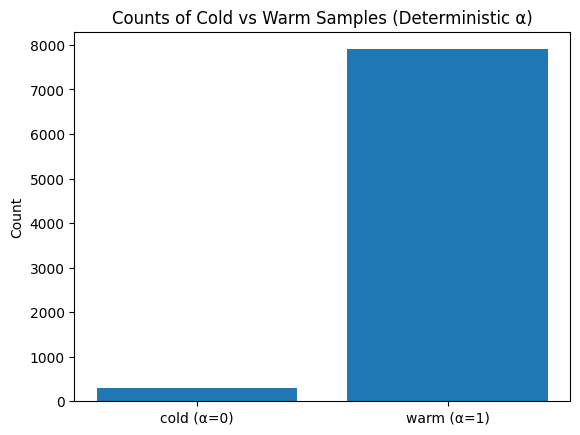

In [119]:
cold_count = int(cold_mask.sum().item())
warm_count = int((~cold_mask).sum().item())

plt.figure()
plt.bar(["cold (α=0)", "warm (α=1)"], [cold_count, warm_count])
plt.title("Counts of Cold vs Warm Samples (Deterministic α)")
plt.ylabel("Count")
plt.show()

In [117]:
text_w = meta_attn["text"].detach().cpu().numpy()
img_w  = meta_attn["image"].detach().cpu().numpy()
time_w = meta_attn["time"].detach().cpu().numpy()

# Mean attention across batch
means = [text_w.mean(), img_w.mean(), time_w.mean()]

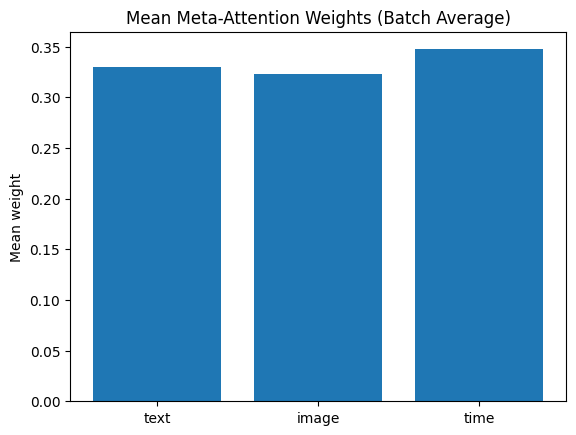

In [122]:
plt.figure()
plt.bar(["text", "image", "time"], means)
plt.title("Mean Meta-Attention Weights (Batch Average)")
plt.ylabel("Mean weight")
plt.show()

# One example sample (pick a cold sample if present; else sample 0)
if cold_mask.any():
    idx0 = int(torch.where(cold_mask)[0][0].item())
else:
    idx0 = 0

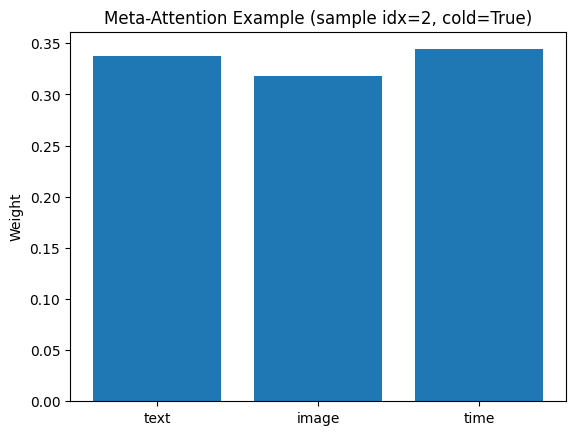

In [123]:
example = [text_w[idx0], img_w[idx0], time_w[idx0]]

plt.figure()
plt.bar(["text", "image", "time"], example)
plt.title(f"Meta-Attention Example (sample idx={idx0}, cold={bool(cold_mask[idx0].item())})")
plt.ylabel("Weight")
plt.show()

This confirms:

* Meta-attention is valid and stable: sums are ~1.0 across the batch, so attention is properly normalised.
* Cold rate is consistent with earlier estimates: 3.53% on an 8,192-row train sample matches the ~3.36% train cold interaction rate we previously measured.
* α behaves exactly as intended (deterministic blend):
  * Warm → α = 1.0 for all warm samples
  * Cold → α = 0.0 for all cold samples



### Saving Meta-Embedding Artifacts

In [128]:
# Directory for artifacts (reuse fusion_artifacts_dir or create meta_artifacts_dir)
meta_artifacts_dir = os.path.join(base_dir, "meta_artifacts")
os.makedirs(meta_artifacts_dir, exist_ok=True)

In [132]:
# meta_config.json
meta_config = {
    "timestamp": datetime.utcnow().isoformat() + "Z",
    "cold_rule": "item_only_fewshot",
    "FEWSHOT_N": int(FEWSHOT_N),

    "text_dim": int(fusion_config["text_dim"]),
    "image_dim": int(fusion_config["image_dim"]),
    "time_dim": int(fusion_config["time_dim"]),

    "meta_dim": int(META_DIM),            # 256
    "id_dim": int(META_DIM),              # item_id_emb dim matched to meta_dim
    "scene_dim": 32,                      # must match UnifiedMetaIDBlock init
    "d_model": int(fusion_config["d_model"]),

    "blend_strategy": "deterministic_alpha",
    "alpha_values": [0.0, 1.0],

    "notes": "MetaEmbeddingGenerator + deterministic alpha blend + UnifiedMetaIDBlock saved for Notebook 08."
}

/tmp/ipython-input-3692233424.py:3: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "timestamp": datetime.utcnow().isoformat() + "Z",


In [133]:
meta_config_path = os.path.join(meta_artifacts_dir, "meta_config.json")
with open(meta_config_path, "w") as f:
    json.dump(meta_config, f, indent=2)

print("Saved:", meta_config_path)

Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/meta_artifacts/meta_config.json


In [134]:
# Save MetaEmbeddingGenerator weights
meta_generator_path = os.path.join(meta_artifacts_dir, "meta_generator.pt")
torch.save(meta_generator.state_dict(), meta_generator_path)
print("Saved:", meta_generator_path)

Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/meta_artifacts/meta_generator.pt


In [135]:
# Save UnifiedMetaIDBlock weights (recommended)
unified_block_path = os.path.join(meta_artifacts_dir, "unified_meta_id_block.pt")
torch.save(unified_block.state_dict(), unified_block_path)
print("Saved:", unified_block_path)

Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/meta_artifacts/unified_meta_id_block.pt


In [136]:
# Save a small debug batch (reproducing purposes)
SAVE_DEBUG_BATCH = True

if SAVE_DEBUG_BATCH:
    # Reuse the last diagnostic batch from Step 5 if available; else sample fresh
    B_debug = 256
    debug_rows = np.random.default_rng(2024).choice(train_idx, size=B_debug, replace=False)
    debug_df = df_id.iloc[debug_rows]
    debug_row_indices = debug_df.index.to_numpy(dtype=np.int64)

    u = torch.tensor(debug_df["user_id_idx"].to_numpy(), dtype=torch.long)
    it = torch.tensor(debug_df["item_id_idx"].to_numpy(), dtype=torch.long)
    sc = torch.tensor(debug_df["scene_idx"].to_numpy(), dtype=torch.long)

    cold_debug = cold_mask_fewshot_item_only(it.to(device)).cpu()

    # Run forward to capture alpha + attention
    text_debug = torch.tensor(
        np.stack([text_embeddings[int(r)] for r in debug_row_indices]),
        dtype=torch.float32,
        device=device
    )
    time_debug = time_features[debug_row_indices].to(device).float()
    image_debug = image_embeddings[it].to(device).float()

    with torch.no_grad():
        out_debug = unified_block(
            user_idx=u.to(device),
            item_idx=it.to(device),
            scene_idx=sc.to(device),
            text_vec=text_debug,
            image_vec=image_debug,
            time_vec=time_debug,
            cold_mask=cold_debug.to(device)
        )

    debug_payload = {
        "row_indices": torch.tensor(debug_row_indices, dtype=torch.long),
        "user_idx": u,
        "item_idx": it,
        "scene_idx": sc,
        "cold_mask": cold_debug,
        "alpha": out_debug["alpha"].cpu(),
        "meta_attention": {k: v.cpu() for k, v in out_debug["meta_attention"].items()}
    }

    debug_path = os.path.join(meta_artifacts_dir, "meta_debug_batch.pt")
    torch.save(debug_payload, debug_path)
    print("Saved:", debug_path)

print("\nmeta artifacts saved successfully")

Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/meta_artifacts/meta_debug_batch.pt

meta artifacts saved successfully
